In [2]:
import pandas as pd

ground_truth = pd.read_csv(
    "train_ground_truth.tsv",
    sep="\t",
    nrows=20
)

source1 = pd.read_csv(
    "train_source1.tsv",
    sep="\t",
    nrows=20
)

source2 = pd.read_csv(
    "train_source2.tsv",
    sep="\t",
    nrows=20
)

source3 = pd.read_csv(
    "train_source3.tsv",
    sep="\t",
    nrows=20
)

print("Files loaded successfully!")

Files loaded successfully!


In [3]:
print("========== GROUND TRUTH ==========")
print("Columns:", ground_truth.columns.tolist())
print(ground_truth.head(10))

print("\n========== SOURCE 1 ==========")
print("Columns:", source1.columns.tolist())
print(source1.head(10))

print("\n========== SOURCE 2 ==========")
print("Columns:", source2.columns.tolist())
print(source2.head(10))

print("\n========== SOURCE 3 ==========")
print("Columns:", source3.columns.tolist())
print(source3.head(10))

========== GROUND TRUTH ==========
Columns: ['source1_entity_id', 'matched_entity_ids']
  source1_entity_id                                 matched_entity_ids
0         S1-965667  S2-681193310,S2-743505751,S3-775321672,S3-1129...
1       S1-55344266  S2-249013014,S2-197070651,S3-478195123,S3-3843...
2      S1-343815751             S2-790675320,S2-479876582,S3-878454467
3      S1-656753428              S2-153058913,S2-24659151,S3-679606215
4      S1-102811957  S2-478959098,S2-553508714,S2-625774905,S3-7280...
5       S1-18727616  S2-755677256,S3-187831601,S3-641489370,S3-4762...
6      S1-318373630                          S2-660036492,S3-804600254
7       S1-86989137                          S3-274817120,S3-312496301
8       S1-29845983                          S2-648035184,S3-588502663
9      S1-789009573              S2-383871912,S3-74481402,S3-576451439

========== SOURCE 1 ==========
Columns: ['entity_id', 'business_name', 'business_address', 'country']
      entity_id             

In [4]:
print("========== SHAPES ==========")

print("Ground Truth:", ground_truth.shape)
print("Source 1:", source1.shape)
print("Source 2:", source2.shape)
print("Source 3:", source3.shape)


print("\n========== COLUMNS ==========")

print("Ground Truth:")
print(ground_truth.columns.tolist())

print("\nSource 1:")
print(source1.columns.tolist())

print("\nSource 2:")
print(source2.columns.tolist())

print("\nSource 3:")
print(source3.columns.tolist())

========== SHAPES ==========
Ground Truth: (20, 2)
Source 1: (20, 4)
Source 2: (20, 4)
Source 3: (20, 4)

========== COLUMNS ==========
Ground Truth:
['source1_entity_id', 'matched_entity_ids']

Source 1:
['entity_id', 'business_name', 'business_address', 'country']

Source 2:
['entity_id', 'business_name', 'business_address', 'country']

Source 3:
['entity_id', 'business_name', 'business_address', 'country']


In [5]:
match_counts = ground_truth["matched_entity_ids"].fillna("").apply(
    lambda x: len([i for i in x.split(",") if i.strip()])
)

print("Match count statistics:")
print(match_counts.describe())

print("\nRecords with 0 matches:", (match_counts == 0).sum())
print("Records with 1 match:", (match_counts == 1).sum())
print("Records with >1 matches:", (match_counts > 1).sum())

Match count statistics:
count    20.000000
mean      3.500000
std       1.670172
min       2.000000
25%       2.000000
50%       3.000000
75%       4.250000
max       7.000000
Name: matched_entity_ids, dtype: float64

Records with 0 matches: 0
Records with 1 match: 0
Records with >1 matches: 20


In [6]:
print("Source 1 IDs:")
print(source1["entity_id"].head(10).tolist())

print("\nSource 2 IDs:")
print(source2["entity_id"].head(10).tolist())

print("\nSource 3 IDs:")
print(source3["entity_id"].head(10).tolist())

Source 1 IDs:
['S1-925783039', 'S1-773889195', 'S1-377745466', 'S1-133037285', 'S1-755362802', 'S1-851869949', 'S1-785847572', 'S1-27541239', 'S1-629417405', 'S1-22305073']

Source 2 IDs:
['S2-166376419', 'S2-764573417', 'S2-639257739', 'S2-163963287', 'S2-49942811', 'S2-138046867', 'S2-584977605', 'S2-277444929', 'S2-721031885', 'S2-508602797']

Source 3 IDs:
['S3-202863386', 'S3-859268022', 'S3-22467283', 'S3-671162755', 'S3-960981775', 'S3-578159284', 'S3-121412624', 'S3-249416830', 'S3-107644605', 'S3-160217003']


In [7]:
def count_rows(file_path):
    total = 0

    for chunk in pd.read_csv(
        file_path,
        sep="\t",
        chunksize=100000
    ):
        total += len(chunk)

    return total


print("Counting rows...")

print("Source 1:", count_rows("train_source1.tsv"))
print("Source 2:", count_rows("train_source2.tsv"))
print("Source 3:", count_rows("train_source3.tsv"))
print("Ground Truth:", count_rows("train_ground_truth.tsv"))

Counting rows...
Source 1: 2206821
Source 2: 5034616
Source 3: 5285603
Ground Truth: 2206821


In [8]:
def missing_value_analysis(file_path):
    missing = None
    total_rows = 0

    for chunk in pd.read_csv(
        file_path,
        sep="\t",
        chunksize=100000
    ):
        total_rows += len(chunk)

        current_missing = chunk.isna().sum()

        if missing is None:
            missing = current_missing
        else:
            missing += current_missing

    result = pd.DataFrame({
        "missing_count": missing,
        "missing_percentage": (missing / total_rows) * 100
    })

    return result


source1_missing = missing_value_analysis(
    "train_source1.tsv"
)

print(source1_missing)

                  missing_count  missing_percentage
entity_id                     0                 0.0
business_name                 0                 0.0
business_address              0                 0.0
country                       0                 0.0


In [9]:
source2_missing = missing_value_analysis(
    "train_source2.tsv"
)

source3_missing = missing_value_analysis(
    "train_source3.tsv"
)

print("========== SOURCE 2 ==========")
print(source2_missing)

print("\n========== SOURCE 3 ==========")
print(source3_missing)

========== SOURCE 2 ==========
                  missing_count  missing_percentage
entity_id                     0            0.000000
business_name                 2            0.000040
business_address         168967            3.356105
country                       0            0.000000

========== SOURCE 3 ==========
                  missing_count  missing_percentage
entity_id                     0            0.000000
business_name                13            0.000246
business_address         175916            3.328211
country                       0            0.000000


In [10]:
def blank_value_analysis(file_path):
    blank_counts = None
    total_rows = 0

    for chunk in pd.read_csv(
        file_path,
        sep="\t",
        chunksize=100000,
        dtype=str
    ):
        total_rows += len(chunk)

        current_blank = (
            chunk
            .fillna("")
            .apply(lambda col: col.str.strip().eq("").sum())
        )

        if blank_counts is None:
            blank_counts = current_blank
        else:
            blank_counts += current_blank

    result = pd.DataFrame({
        "blank_count": blank_counts,
        "blank_percentage": (blank_counts / total_rows) * 100
    })

    return result

In [11]:
print("========== SOURCE 1 ==========")
print(blank_value_analysis("train_source1.tsv"))

print("\n========== SOURCE 2 ==========")
print(blank_value_analysis("train_source2.tsv"))

print("\n========== SOURCE 3 ==========")
print(blank_value_analysis("train_source3.tsv"))

========== SOURCE 1 ==========
                  blank_count  blank_percentage
entity_id                   0               0.0
business_name               0               0.0
business_address            0               0.0
country                     0               0.0

========== SOURCE 2 ==========
                  blank_count  blank_percentage
entity_id                   0          0.000000
business_name               2          0.000040
business_address       168967          3.356105
country                     0          0.000000

========== SOURCE 3 ==========
                  blank_count  blank_percentage
entity_id                   0          0.000000
business_name              13          0.000246
business_address       175916          3.328211
country                     0          0.000000


In [12]:
def duplicate_id_analysis(file_path):
    duplicate_count = 0
    total_rows = 0
    unique_ids = set()

    for chunk in pd.read_csv(
        file_path,
        sep="\t",
        chunksize=100000,
        usecols=["entity_id"],
        dtype=str
    ):
        total_rows += len(chunk)

        # Count IDs already seen in previous chunks
        for entity_id in chunk["entity_id"]:
            if entity_id in unique_ids:
                duplicate_count += 1
            else:
                unique_ids.add(entity_id)

    return total_rows, len(unique_ids), duplicate_count


for name, file in [
    ("Source 1", "train_source1.tsv"),
    ("Source 2", "train_source2.tsv"),
    ("Source 3", "train_source3.tsv")
]:
    total, unique, duplicates = duplicate_id_analysis(file)

    print(f"\n{name}")
    print("Total records :", total)
    print("Unique IDs    :", unique)
    print("Duplicate IDs :", duplicates)


Source 1
Total records : 2206821
Unique IDs    : 2206821
Duplicate IDs : 0

Source 2
Total records : 5034616
Unique IDs    : 5034616
Duplicate IDs : 0

Source 3
Total records : 5285603
Unique IDs    : 5285603
Duplicate IDs : 0


In [13]:
def analyze_ground_truth(file_path):
    total_s1 = 0
    total_matches = 0
    s2_matches = 0
    s3_matches = 0

    for chunk in pd.read_csv(
        file_path,
        sep="\t",
        chunksize=100000,
        dtype=str
    ):
        total_s1 += len(chunk)

        for value in chunk["matched_entity_ids"].fillna(""):
            ids = [
                x.strip()
                for x in value.split(",")
                if x.strip()
            ]

            total_matches += len(ids)

            s2_matches += sum(
                x.startswith("S2-")
                for x in ids
            )

            s3_matches += sum(
                x.startswith("S3-")
                for x in ids
            )

    return total_s1, total_matches, s2_matches, s3_matches


result = analyze_ground_truth(
    "train_ground_truth.tsv"
)

print("Source 1 entities:", result[0])
print("Total positive matches:", result[1])
print("Source 2 positive matches:", result[2])
print("Source 3 positive matches:", result[3])

Source 1 entities: 2206821
Total positive matches: 7638365
Source 2 positive matches: 3693619
Source 3 positive matches: 3944746


In [14]:
match_counts = []

for chunk in pd.read_csv(
    "train_ground_truth.tsv",
    sep="\t",
    chunksize=100000,
    dtype=str
):
    counts = (
        chunk["matched_entity_ids"]
        .fillna("")
        .str.split(",")
        .apply(lambda x: len([i for i in x if i.strip()]))
    )

    match_counts.extend(counts.tolist())

match_counts = pd.Series(match_counts)

print("Total Source-1 entities:", len(match_counts))
print("Average matches:", match_counts.mean())
print("Median matches:", match_counts.median())
print("Minimum matches:", match_counts.min())
print("Maximum matches:", match_counts.max())

print("\nDistribution:")
print(match_counts.value_counts().sort_index())


Total Source-1 entities: 2206821
Average matches: 3.4612526344456573
Median matches: 3.0
Minimum matches: 0
Maximum matches: 11

Distribution:
0     123247
1     119157
2     375212
3     530841
4     484115
5     321957
6     164868
7      63968
8      18680
9       4205
10       534
11        37
Name: count, dtype: int64


In [15]:
import numpy as np

# Read only the Source-1 IDs from ground truth
ground_truth_ids = pd.read_csv(
    "train_ground_truth.tsv",
    sep="\t",
    usecols=["source1_entity_id"],
    dtype=str
)

print("Total Source-1 entities:", len(ground_truth_ids))

# Reproducible random generator
rng = np.random.default_rng(42)

# Shuffle indices
indices = np.arange(len(ground_truth_ids))
rng.shuffle(indices)

# 80% train / 20% validation
split_point = int(0.80 * len(indices))

train_indices = indices[:split_point]
val_indices = indices[split_point:]

train_s1_ids = ground_truth_ids.iloc[train_indices]["source1_entity_id"]
val_s1_ids = ground_truth_ids.iloc[val_indices]["source1_entity_id"]

print("Training entities:", len(train_s1_ids))
print("Validation entities:", len(val_s1_ids))

print("\nTrain percentage:",
      len(train_s1_ids) / len(ground_truth_ids) * 100)

print("Validation percentage:",
      len(val_s1_ids) / len(ground_truth_ids) * 100)

Total Source-1 entities: 2206821
Training entities: 1765456
Validation entities: 441365

Train percentage: 79.99996374875896
Validation percentage: 20.00003625124104


In [16]:
# Load a small sample from each source
s1_sample = pd.read_csv(
    "train_source1.tsv",
    sep="\t",
    nrows=100000,
    dtype=str
)

s2_sample = pd.read_csv(
    "train_source2.tsv",
    sep="\t",
    nrows=100000,
    dtype=str
)

s3_sample = pd.read_csv(
    "train_source3.tsv",
    sep="\t",
    nrows=100000,
    dtype=str
)

print("Source 1 countries:")
print(s1_sample["country"].value_counts().head(20))

print("\nSource 2 countries:")
print(s2_sample["country"].value_counts().head(20))

print("\nSource 3 countries:")
print(s3_sample["country"].value_counts().head(20))


Source 1 countries:
country
US       59890
India    40110
Name: count, dtype: int64

Source 2 countries:
country
US       59936
India    40064
Name: count, dtype: int64

Source 3 countries:
country
US       59529
India    40471
Name: count, dtype: int64


In [17]:
import re
import unicodedata


def normalize_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Convert Unicode characters to a consistent representation
    text = unicodedata.normalize("NFKD", text)

    # Lowercase
    text = text.lower()

    # Remove accents
    text = "".join(
        c for c in text
        if not unicodedata.combining(c)
    )

    # Replace punctuation with spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [18]:
def normalize_business_name(text):
    text = normalize_text(text)

    # Common business abbreviations
    replacements = {
        "private limited": "pvt ltd",
        "private ltd": "pvt ltd",
        "limited": "ltd",
        "corporation": "corp",
        "incorporated": "inc",
        "company": "co"
    }

    for old, new in replacements.items():
        text = re.sub(
            rf"\b{old}\b",
            new,
            text
        )

    # Remove common business suffixes
    tokens = text.split()

    return " ".join(tokens)

In [19]:
def normalize_address(text):
    text = normalize_text(text)

    replacements = {
        "street": "st",
        "road": "rd",
        "avenue": "ave",
        "boulevard": "blvd",
        "drive": "dr",
        "lane": "ln",
        "highway": "hwy",
        "parkway": "pkwy",
        "apartment": "apt",
        "suite": "ste"
    }

    for old, new in replacements.items():
        text = re.sub(
            rf"\b{old}\b",
            new,
            text
        )

    return text

In [20]:
test_names = [
    "ABC Technologies Pvt. Ltd.",
    "ABC Technologies Private Limited",
    "ABC TECHNOLOGIES PVT LTD",
    "Microsoft Corporation"
]

print("NAME NORMALIZATION")
print("-" * 50)

for name in test_names:
    print(name)
    print("→", normalize_business_name(name))
    print()

NAME NORMALIZATION
--------------------------------------------------
ABC Technologies Pvt. Ltd.
→ abc technologies pvt ltd

ABC Technologies Private Limited
→ abc technologies pvt ltd

ABC TECHNOLOGIES PVT LTD
→ abc technologies pvt ltd

Microsoft Corporation
→ microsoft corp



In [21]:
test_addresses = [
    "1795 Westchester Drive, High Point, NC",
    "1795 Westchester Dr., High Point NC",
    "2100 Cameron Drive, Unit G, Dundalk, MD"
]

print("ADDRESS NORMALIZATION")
print("-" * 50)

for address in test_addresses:
    print(address)
    print("→", normalize_address(address))
    print()

ADDRESS NORMALIZATION
--------------------------------------------------
1795 Westchester Drive, High Point, NC
→ 1795 westchester dr high point nc

1795 Westchester Dr., High Point NC
→ 1795 westchester dr high point nc

2100 Cameron Drive, Unit G, Dundalk, MD
→ 2100 cameron dr unit g dundalk md



In [22]:
from rapidfuzz.fuzz import ratio

print("RapidFuzz is working!")

RapidFuzz is working!


In [23]:
def pair_features(record_a, record_b):
    name_a = normalize_business_name(record_a["business_name"])
    name_b = normalize_business_name(record_b["business_name"])

    address_a = normalize_address(record_a["business_address"])
    address_b = normalize_address(record_b["business_address"])

    country_a = str(record_a["country"]).strip().lower()
    country_b = str(record_b["country"]).strip().lower()

    return {
        "name_exact": int(
            name_a == name_b and name_a != ""
        ),

        "name_similarity": ratio(
            name_a,
            name_b
        ) / 100,

        "address_exact": int(
            address_a == address_b and address_a != ""
        ),

        "address_similarity": ratio(
            address_a,
            address_b
        ) / 100,

        "country_match": int(
            country_a == country_b
        )
    }

print("Feature function created!")

Feature function created!


In [24]:
record_a = {
    "business_name": "ABC Technologies Pvt. Ltd.",
    "business_address": "1795 Westchester Drive, High Point, NC",
    "country": "US"
}

record_b = {
    "business_name": "ABC Technologies Private Limited",
    "business_address": "1795 Westchester Dr., High Point NC",
    "country": "US"
}

features = pair_features(record_a, record_b)

print(features)

{'name_exact': 1, 'name_similarity': 1.0, 'address_exact': 1, 'address_similarity': 1.0, 'country_match': 1}


In [25]:
# ==========================================
# STEP 15: Inspect Ground Truth Match IDs
# ==========================================

import pandas as pd

gt_sample = pd.read_csv(
    "train_ground_truth.tsv",
    sep="\t",
    nrows=5
)

print("Ground Truth sample:")
display(gt_sample)

print("\nColumns:")
print(gt_sample.columns.tolist())

print("\nFirst matched_entity_ids:")
for value in gt_sample["matched_entity_ids"]:
    print(value)

Ground Truth sample:


,source1_entity_id,matched_entity_ids
0,S1-965667,"S2-681193310,S2-743505751,S3-775321672,S3-1129..."
1,S1-55344266,"S2-249013014,S2-197070651,S3-478195123,S3-3843..."
2,S1-343815751,"S2-790675320,S2-479876582,S3-878454467"
3,S1-656753428,"S2-153058913,S2-24659151,S3-679606215"
4,S1-102811957,"S2-478959098,S2-553508714,S2-625774905,S3-7280..."



Columns:
['source1_entity_id', 'matched_entity_ids']

First matched_entity_ids:
S2-681193310,S2-743505751,S3-775321672,S3-11291185,S3-860443364
S2-249013014,S2-197070651,S3-478195123,S3-384364074
S2-790675320,S2-479876582,S3-878454467
S2-153058913,S2-24659151,S3-679606215
S2-478959098,S2-553508714,S2-625774905,S3-728090388,S3-928796641,S3-449308785


In [26]:
# ==========================================
# STEP 16: Create Positive Matching Pairs
# ==========================================

positive_pairs = []

for _, row in gt_sample.iterrows():

    source1_id = row["source1_entity_id"]

    matched_ids = str(row["matched_entity_ids"]).split(",")

    for matched_id in matched_ids:

        matched_id = matched_id.strip()

        if matched_id:
            positive_pairs.append({
                "source1_entity_id": source1_id,
                "matched_entity_id": matched_id,
                "label": 1
            })

positive_pairs_df = pd.DataFrame(positive_pairs)

print("Positive pairs created:", len(positive_pairs_df))

print("\nSample positive pairs:")
display(positive_pairs_df)

Positive pairs created: 21

Sample positive pairs:


,source1_entity_id,matched_entity_id,label
0,S1-965667,S2-681193310,1
1,S1-965667,S2-743505751,1
2,S1-965667,S3-775321672,1
3,S1-965667,S3-11291185,1
4,S1-965667,S3-860443364,1
5,S1-55344266,S2-249013014,1
6,S1-55344266,S2-197070651,1
7,S1-55344266,S3-478195123,1
8,S1-55344266,S3-384364074,1
9,S1-343815751,S2-790675320,1


In [27]:
# ==========================================
# STEP 17: Generate ALL Positive Pairs
# Memory-efficient chunk processing
# ==========================================

import pandas as pd

INPUT_FILE = "train_ground_truth.tsv"
OUTPUT_FILE = "positive_pairs.tsv"

CHUNK_SIZE = 100_000

first_chunk = True
total_pairs = 0

for chunk in pd.read_csv(
    INPUT_FILE,
    sep="\t",
    chunksize=CHUNK_SIZE
):

    pairs = []

    for _, row in chunk.iterrows():

        source1_id = row["source1_entity_id"]

        matched_ids = str(row["matched_entity_ids"]).split(",")

        for matched_id in matched_ids:

            matched_id = matched_id.strip()

            if matched_id:
                pairs.append({
                    "source1_entity_id": source1_id,
                    "matched_entity_id": matched_id,
                    "label": 1
                })

    pairs_df = pd.DataFrame(pairs)

    pairs_df.to_csv(
        OUTPUT_FILE,
        sep="\t",
        index=False,
        mode="w" if first_chunk else "a",
        header=first_chunk
    )

    total_pairs += len(pairs_df)
    first_chunk = False

    print(
        f"Processed {len(chunk):,} ground-truth rows | "
        f"Positive pairs so far: {total_pairs:,}"
    )

print("\n========================================")
print("POSITIVE PAIR GENERATION COMPLETE")
print("========================================")
print(f"Total positive pairs: {total_pairs:,}")
print(f"Saved to: {OUTPUT_FILE}")

Processed 100,000 ground-truth rows | Positive pairs so far: 351,591
Processed 100,000 ground-truth rows | Positive pairs so far: 704,263
Processed 100,000 ground-truth rows | Positive pairs so far: 1,055,531
Processed 100,000 ground-truth rows | Positive pairs so far: 1,407,003
Processed 100,000 ground-truth rows | Positive pairs so far: 1,758,539
Processed 100,000 ground-truth rows | Positive pairs so far: 2,109,874
Processed 100,000 ground-truth rows | Positive pairs so far: 2,461,452
Processed 100,000 ground-truth rows | Positive pairs so far: 2,813,288
Processed 100,000 ground-truth rows | Positive pairs so far: 3,164,573
Processed 100,000 ground-truth rows | Positive pairs so far: 3,516,836
Processed 100,000 ground-truth rows | Positive pairs so far: 3,868,522
Processed 100,000 ground-truth rows | Positive pairs so far: 4,220,904
Processed 100,000 ground-truth rows | Positive pairs so far: 4,571,545
Processed 100,000 ground-truth rows | Positive pairs so far: 4,923,135
Processed 

In [28]:
# ==========================================
# STEP 18: Load Positive Pairs
# ==========================================

import pandas as pd

positive_pairs = pd.read_csv(
    "positive_pairs.tsv",
    sep="\t"
)

print("Positive pairs loaded successfully!")
print("Shape:", positive_pairs.shape)

print("\nColumns:")
print(positive_pairs.columns.tolist())

print("\nSample:")
display(positive_pairs.head(10))

Positive pairs loaded successfully!
Shape: (7761612, 3)

Columns:
['source1_entity_id', 'matched_entity_id', 'label']

Sample:


,source1_entity_id,matched_entity_id,label
0,S1-965667,S2-681193310,1
1,S1-965667,S2-743505751,1
2,S1-965667,S3-775321672,1
3,S1-965667,S3-11291185,1
4,S1-965667,S3-860443364,1
5,S1-55344266,S2-249013014,1
6,S1-55344266,S2-197070651,1
7,S1-55344266,S3-478195123,1
8,S1-55344266,S3-384364074,1
9,S1-343815751,S2-790675320,1


In [29]:
# ==========================================
# STEP 19A: Check Positive Pair Distribution
# ==========================================

print("Total positive pairs:", len(positive_pairs))

print("\nSource distribution:")
print(
    positive_pairs["matched_entity_id"]
    .str[:2]
    .value_counts()
)

print("\nLabels:")
print(positive_pairs["label"].value_counts())

print("\nUnique Source-1 entities:")
print(positive_pairs["source1_entity_id"].nunique())

print("\nUnique matched entities:")
print(positive_pairs["matched_entity_id"].nunique())

Total positive pairs: 7761612

Source distribution:
matched_entity_id
S3    3944746
S2    3693619
Name: count, dtype: int64

Labels:
label
1    7761612
Name: count, dtype: int64

Unique Source-1 entities:
2206821

Unique matched entities:
7638365


In [30]:
import pandas as pd
import re
from rapidfuzz.fuzz import ratio

# ==========================================
# STEP 19B: NORMALIZATION FUNCTIONS
# ==========================================

def normalize_name(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Remove punctuation
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Standardize common business terms
    replacements = {
        r"\bprivate limited\b": "pvt ltd",
        r"\bprivate ltd\b": "pvt ltd",
        r"\bcorporation\b": "corp",
        r"\bincorporated\b": "inc",
        r"\blimited\b": "ltd",
        r"\bcompany\b": "co",
    }

    for pattern, replacement in replacements.items():
        text = re.sub(pattern, replacement, text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


def normalize_address(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Remove punctuation
    text = re.sub(r"[,.#]", " ", text)

    # Standardize common address terms
    replacements = {
        r"\bdrive\b": "dr",
        r"\bstreet\b": "st",
        r"\broad\b": "rd",
        r"\bavenue\b": "ave",
        r"\bboulevard\b": "blvd",
        r"\blane\b": "ln",
        r"\bhighway\b": "hwy",
        r"\bparkway\b": "pkwy",
        r"\bplace\b": "pl",
        r"\bcourt\b": "ct",
        r"\bsuite\b": "ste",
        r"\bapartment\b": "apt",
    }

    for pattern, replacement in replacements.items():
        text = re.sub(pattern, replacement, text)

    text = re.sub(r"\s+", " ", text).strip()

    return text


print("Normalization functions ready.")

Normalization functions ready.


In [31]:
# ==========================================
# STEP 19C: TEST NORMALIZATION
# ==========================================

test_names = [
    "ABC Technologies Pvt. Ltd.",
    "ABC Technologies Private Limited",
    "ABC TECHNOLOGIES PVT LTD",
    "Microsoft Corporation"
]

print("NAME NORMALIZATION")
print("-" * 50)

for name in test_names:
    print(name)
    print("→", normalize_name(name))
    print()


test_addresses = [
    "1795 Westchester Drive, High Point, NC",
    "1795 Westchester Dr., High Point NC",
    "2100 Cameron Drive, Unit G, Dundalk, MD"
]

print("ADDRESS NORMALIZATION")
print("-" * 50)

for address in test_addresses:
    print(address)
    print("→", normalize_address(address))
    print()

NAME NORMALIZATION
--------------------------------------------------
ABC Technologies Pvt. Ltd.
→ abc technologies pvt ltd

ABC Technologies Private Limited
→ abc technologies pvt ltd

ABC TECHNOLOGIES PVT LTD
→ abc technologies pvt ltd

Microsoft Corporation
→ microsoft corp

ADDRESS NORMALIZATION
--------------------------------------------------
1795 Westchester Drive, High Point, NC
→ 1795 westchester dr high point nc

1795 Westchester Dr., High Point NC
→ 1795 westchester dr high point nc

2100 Cameron Drive, Unit G, Dundalk, MD
→ 2100 cameron dr unit g dundalk md



In [32]:
# ==========================================
# STEP 20: LOAD SOURCE RECORDS FOR MATCHING
# ==========================================

# Load Source 1
source1_full = pd.read_csv(
    "train_source1.tsv",
    sep="\t",
    dtype=str
)

# Load Source 2
source2_full = pd.read_csv(
    "train_source2.tsv",
    sep="\t",
    dtype=str
)

# Load Source 3
source3_full = pd.read_csv(
    "train_source3.tsv",
    sep="\t",
    dtype=str
)

print("Source 1:", source1_full.shape)
print("Source 2:", source2_full.shape)
print("Source 3:", source3_full.shape)

Source 1: (2206821, 4)
Source 2: (5034616, 4)
Source 3: (5285603, 4)


In [33]:
# ==========================================
# STEP 21: CREATE ID LOOKUP TABLES
# ==========================================

# Keep only the columns needed for feature generation
s1_lookup = source1_full.set_index("entity_id")[
    ["business_name", "business_address", "country"]
]

s2_lookup = source2_full.set_index("entity_id")[
    ["business_name", "business_address", "country"]
]

s3_lookup = source3_full.set_index("entity_id")[
    ["business_name", "business_address", "country"]
]

print("Lookup tables created.")

print("S1 lookup:", s1_lookup.shape)
print("S2 lookup:", s2_lookup.shape)
print("S3 lookup:", s3_lookup.shape)

Lookup tables created.
S1 lookup: (2206821, 3)
S2 lookup: (5034616, 3)
S3 lookup: (5285603, 3)


In [34]:
# ==========================================
# STEP 22: FEATURE GENERATION TEST
# ==========================================

def calculate_pair_features(s1_id, matched_id):
    
    # Get Source 1 record
    r1 = s1_lookup.loc[s1_id]

    # Determine whether match is Source 2 or Source 3
    if matched_id.startswith("S2-"):
        r2 = s2_lookup.loc[matched_id]
    elif matched_id.startswith("S3-"):
        r2 = s3_lookup.loc[matched_id]
    else:
        return None

    # Normalize fields
    name1 = normalize_name(r1["business_name"])
    name2 = normalize_name(r2["business_name"])

    address1 = normalize_address(r1["business_address"])
    address2 = normalize_address(r2["business_address"])

    country1 = str(r1["country"]).lower().strip()
    country2 = str(r2["country"]).lower().strip()

    # Similarities
    name_similarity = ratio(name1, name2) / 100
    address_similarity = ratio(address1, address2) / 100

    return {
        "source1_entity_id": s1_id,
        "matched_entity_id": matched_id,
        "name_exact": int(name1 == name2 and name1 != ""),
        "name_similarity": name_similarity,
        "address_exact": int(address1 == address2 and address1 != ""),
        "address_similarity": address_similarity,
        "country_match": int(country1 == country2),
        "label": 1
    }


# Test on first 10 positive pairs
test_features = []

for _, row in positive_pairs.head(10).iterrows():
    features = calculate_pair_features(
        row["source1_entity_id"],
        row["matched_entity_id"]
    )
    test_features.append(features)

test_features_df = pd.DataFrame(test_features)

display(test_features_df)

,source1_entity_id,matched_entity_id,name_exact,name_similarity,address_exact,address_similarity,country_match,label
0,S1-965667,S2-681193310,0,0.964286,0,0.000000,1,1
1,S1-965667,S2-743505751,0,0.923077,0,0.000000,1,1
2,S1-965667,S3-775321672,0,0.228571,0,0.742857,1,1
3,S1-965667,S3-11291185,0,0.888889,0,0.716418,1,1
4,S1-965667,S3-860443364,0,0.679245,0,0.000000,1,1
5,S1-55344266,S2-249013014,0,0.000000,1,1.000000,1,1
6,S1-55344266,S2-197070651,1,1.000000,1,1.000000,1,1
7,S1-55344266,S3-478195123,0,0.882353,0,0.925926,1,1
8,S1-55344266,S3-384364074,0,0.000000,0,0.834783,1,1
9,S1-343815751,S2-790675320,0,0.736842,0,0.477612,1,1


In [35]:
# ==========================================
# STEP 23: FULL FEATURE GENERATION
# ==========================================

import os
import numpy as np

OUTPUT_FILE = "positive_features.tsv"

CHUNK_SIZE = 100_000

# Remove old output if it exists
if os.path.exists(OUTPUT_FILE):
    os.remove(OUTPUT_FILE)

total_pairs = len(positive_pairs)

print("=" * 60)
print("STARTING FULL FEATURE GENERATION")
print("=" * 60)
print("Total pairs:", f"{total_pairs:,}")
print("Chunk size:", f"{CHUNK_SIZE:,}")
print("Expected chunks:", (total_pairs + CHUNK_SIZE - 1) // CHUNK_SIZE)


def process_feature_chunk(chunk):

    # --------------------------------------
    # Source 1 lookup
    # --------------------------------------
    s1 = s1_lookup.reindex(
        chunk["source1_entity_id"].values
    ).reset_index(drop=True)

    # --------------------------------------
    # Split S2 / S3
    # --------------------------------------
    s2_mask = chunk["matched_entity_id"].str.startswith("S2-")
    s3_mask = ~s2_mask

    # --------------------------------------
    # Create result DataFrame
    # --------------------------------------
    result = chunk[
        ["source1_entity_id", "matched_entity_id", "label"]
    ].copy()

    result["name_exact"] = 0
    result["name_similarity"] = 0.0
    result["address_exact"] = 0
    result["address_similarity"] = 0.0
    result["country_match"] = 0

    # ======================================
    # Process S2 pairs
    # ======================================

    if s2_mask.any():

        s2_ids = chunk.loc[
            s2_mask, "matched_entity_id"
        ].values

        s2 = s2_lookup.reindex(s2_ids).reset_index(drop=True)

        s1_s2 = s1.loc[s2_mask.values].reset_index(drop=True)

        name1 = s1_s2["business_name"].fillna("").map(normalize_name)
        name2 = s2["business_name"].fillna("").map(normalize_name)

        addr1 = s1_s2["business_address"].fillna("").map(normalize_address)
        addr2 = s2["business_address"].fillna("").map(normalize_address)

        country1 = s1_s2["country"].fillna("").astype(str).str.lower().str.strip()
        country2 = s2["country"].fillna("").astype(str).str.lower().str.strip()

        result.loc[s2_mask, "name_exact"] = (
            (name1 == name2) & (name1 != "")
        ).astype(int).values

        result.loc[s2_mask, "name_similarity"] = [
            ratio(a, b) / 100
            for a, b in zip(name1, name2)
        ]

        result.loc[s2_mask, "address_exact"] = (
            (addr1 == addr2) & (addr1 != "")
        ).astype(int).values

        result.loc[s2_mask, "address_similarity"] = [
            ratio(a, b) / 100
            for a, b in zip(addr1, addr2)
        ]

        result.loc[s2_mask, "country_match"] = (
            country1 == country2
        ).astype(int).values

    # ======================================
    # Process S3 pairs
    # ======================================

    if s3_mask.any():

        s3_ids = chunk.loc[
            s3_mask, "matched_entity_id"
        ].values

        s3 = s3_lookup.reindex(s3_ids).reset_index(drop=True)

        s1_s3 = s1.loc[s3_mask.values].reset_index(drop=True)

        name1 = s1_s3["business_name"].fillna("").map(normalize_name)
        name2 = s3["business_name"].fillna("").map(normalize_name)

        addr1 = s1_s3["business_address"].fillna("").map(normalize_address)
        addr2 = s3["business_address"].fillna("").map(normalize_address)

        country1 = s1_s3["country"].fillna("").astype(str).str.lower().str.strip()
        country2 = s3["country"].fillna("").astype(str).str.lower().str.strip()

        result.loc[s3_mask, "name_exact"] = (
            (name1 == name2) & (name1 != "")
        ).astype(int).values

        result.loc[s3_mask, "name_similarity"] = [
            ratio(a, b) / 100
            for a, b in zip(name1, name2)
        ]

        result.loc[s3_mask, "address_exact"] = (
            (addr1 == addr2) & (addr1 != "")
        ).astype(int).values

        result.loc[s3_mask, "address_similarity"] = [
            ratio(a, b) / 100
            for a, b in zip(addr1, addr2)
        ]

        result.loc[s3_mask, "country_match"] = (
            country1 == country2
        ).astype(int).values

    return result


# ==========================================
# PROCESS CHUNKS
# ==========================================

for start in range(0, total_pairs, CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, total_pairs)

    chunk = positive_pairs.iloc[start:end]

    features_chunk = process_feature_chunk(chunk)

    # Append to TSV
    features_chunk.to_csv(
        OUTPUT_FILE,
        sep="\t",
        index=False,
        mode="a",
        header=(start == 0)
    )

    print(
        f"Processed {end:,}/{total_pairs:,} "
        f"({end / total_pairs * 100:.2f}%)"
    )


print("=" * 60)
print("FEATURE GENERATION COMPLETE")
print("=" * 60)
print("Saved to:", OUTPUT_FILE)

STARTING FULL FEATURE GENERATION
Total pairs: 7,761,612
Chunk size: 100,000
Expected chunks: 78
Processed 100,000/7,761,612 (1.29%)
Processed 200,000/7,761,612 (2.58%)
Processed 300,000/7,761,612 (3.87%)
Processed 400,000/7,761,612 (5.15%)
Processed 500,000/7,761,612 (6.44%)
Processed 600,000/7,761,612 (7.73%)
Processed 700,000/7,761,612 (9.02%)
Processed 800,000/7,761,612 (10.31%)
Processed 900,000/7,761,612 (11.60%)
Processed 1,000,000/7,761,612 (12.88%)
Processed 1,100,000/7,761,612 (14.17%)
Processed 1,200,000/7,761,612 (15.46%)
Processed 1,300,000/7,761,612 (16.75%)
Processed 1,400,000/7,761,612 (18.04%)
Processed 1,500,000/7,761,612 (19.33%)
Processed 1,600,000/7,761,612 (20.61%)
Processed 1,700,000/7,761,612 (21.90%)
Processed 1,800,000/7,761,612 (23.19%)
Processed 1,900,000/7,761,612 (24.48%)
Processed 2,000,000/7,761,612 (25.77%)
Processed 2,100,000/7,761,612 (27.06%)
Processed 2,200,000/7,761,612 (28.34%)
Processed 2,300,000/7,761,612 (29.63%)
Processed 2,400,000/7,761,612 (3

In [36]:
# ==========================================
# STEP 24: VERIFY POSITIVE FEATURES
# ==========================================

positive_features = pd.read_csv(
    "positive_features.tsv",
    sep="\t",
    dtype={
        "source1_entity_id": str,
        "matched_entity_id": str,
        "label": "int8"
    }
)

print("Shape:", positive_features.shape)

print("\nColumns:")
print(positive_features.columns.tolist())

print("\nLabel distribution:")
print(positive_features["label"].value_counts())

print("\nMissing values:")
print(positive_features.isnull().sum())

print("\nSample:")
display(positive_features.head(10))

Shape: (7761612, 8)

Columns:
['source1_entity_id', 'matched_entity_id', 'label', 'name_exact', 'name_similarity', 'address_exact', 'address_similarity', 'country_match']

Label distribution:
label
1    7761612
Name: count, dtype: int64

Missing values:
source1_entity_id          0
matched_entity_id     123247
label                      0
name_exact                 0
name_similarity            0
address_exact              0
address_similarity         0
country_match              0
dtype: int64

Sample:


,source1_entity_id,matched_entity_id,label,name_exact,name_similarity,address_exact,address_similarity,country_match
0,S1-965667,S2-681193310,1,0,0.964286,0,0.000000,1
1,S1-965667,S2-743505751,1,0,0.923077,0,0.000000,1
2,S1-965667,S3-775321672,1,0,0.228571,0,0.742857,1
3,S1-965667,S3-11291185,1,0,0.888889,0,0.716418,1
4,S1-965667,S3-860443364,1,0,0.679245,0,0.000000,1
5,S1-55344266,S2-249013014,1,0,0.000000,1,1.000000,1
6,S1-55344266,S2-197070651,1,1,1.000000,1,1.000000,1
7,S1-55344266,S3-478195123,1,0,0.882353,0,0.925926,1
8,S1-55344266,S3-384364074,1,0,0.000000,0,0.834783,1
9,S1-343815751,S2-790675320,1,0,0.736842,0,0.477612,1


In [37]:
# ==========================================
# STEP 25: CHECK POSITIVE FEATURE DATA
# ==========================================

print("Positive features shape:", positive_features.shape)

print("\nLabel distribution:")
print(positive_features["label"].value_counts())

print("\nMissing values:")
print(positive_features.isnull().sum())

print("\nFeature statistics:")
display(
    positive_features[
        [
            "name_exact",
            "name_similarity",
            "address_exact",
            "address_similarity",
            "country_match"
        ]
    ].describe()
)

Positive features shape: (7761612, 8)

Label distribution:
label
1    7761612
Name: count, dtype: int64

Missing values:
source1_entity_id          0
matched_entity_id     123247
label                      0
name_exact                 0
name_similarity            0
address_exact              0
address_similarity         0
country_match              0
dtype: int64

Feature statistics:


,name_exact,name_similarity,address_exact,address_similarity,country_match
count,7.761612e+06,7.761612e+06,7.761612e+06,7.761612e+06,7.761612e+06
mean,2.347508e-01,7.810099e-01,1.117201e-01,7.479029e-01,9.841210e-01
std,4.238430e-01,2.793148e-01,3.150218e-01,2.539804e-01,1.250076e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,7.307692e-01,0.000000e+00,6.368159e-01,1.000000e+00
50%,0.000000e+00,8.750000e-01,0.000000e+00,8.311688e-01,1.000000e+00
75%,0.000000e+00,9.714286e-01,0.000000e+00,9.230769e-01,1.000000e+00
max,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [38]:
# ==========================================
# STEP 38: PREPARE POSITIVE PAIRS
# ==========================================

positive_pairs = positive_features[
    [
        "source1_entity_id",
        "matched_entity_id",
        "name_exact",
        "name_similarity",
        "address_exact",
        "address_similarity",
        "country_match",
        "label"
    ]
].copy()

# Remove rows where matched entity is missing
positive_pairs = positive_pairs.dropna(
    subset=["matched_entity_id"]
).reset_index(drop=True)

print("Positive pairs after removing missing IDs:",
      len(positive_pairs))

print("\nLabel distribution:")
print(positive_pairs["label"].value_counts())

print("\nShape:")
print(positive_pairs.shape)

Positive pairs after removing missing IDs: 7638365

Label distribution:
label
1    7638365
Name: count, dtype: int64

Shape:
(7638365, 8)


In [39]:
# ==========================================
# STEP 39: GENERATE NEGATIVE PAIRS
# ==========================================

import numpy as np
import pandas as pd

NEGATIVE_TARGET = 500_000

print("Generating negative pairs...")
print("Target:", NEGATIVE_TARGET)

# ------------------------------------------------
# Load only entity IDs from Source 1, 2 and 3
# ------------------------------------------------

s1_ids = pd.read_csv(
    "train_source1.tsv",
    sep="\t",
    usecols=["entity_id"],
    dtype=str
)["entity_id"].dropna().unique()

s2_ids = pd.read_csv(
    "train_source2.tsv",
    sep="\t",
    usecols=["entity_id"],
    dtype=str
)["entity_id"].dropna().unique()

s3_ids = pd.read_csv(
    "train_source3.tsv",
    sep="\t",
    usecols=["entity_id"],
    dtype=str
)["entity_id"].dropna().unique()

print("Source 1 IDs:", len(s1_ids))
print("Source 2 IDs:", len(s2_ids))
print("Source 3 IDs:", len(s3_ids))

# ------------------------------------------------
# Combine Source 2 + Source 3 candidate IDs
# ------------------------------------------------

target_ids = np.concatenate([
    s2_ids,
    s3_ids
])

print("Total target IDs:", len(target_ids))

# ------------------------------------------------
# Generate random candidate pairs
# ------------------------------------------------

rng = np.random.default_rng(42)

negative_chunks = []
total_collected = 0

while total_collected < NEGATIVE_TARGET:

    batch_size = min(
        700_000,
        max(100_000, (NEGATIVE_TARGET - total_collected) * 2)
    )

    source1_sample = rng.choice(
        s1_ids,
        size=batch_size,
        replace=True
    )

    target_sample = rng.choice(
        target_ids,
        size=batch_size,
        replace=True
    )

    candidates = pd.DataFrame({
        "source1_entity_id": source1_sample,
        "matched_entity_id": target_sample
    })

    # Remove duplicate candidate pairs
    candidates = candidates.drop_duplicates()

    # ------------------------------------------------
    # Remove pairs that are actually known positives
    # ------------------------------------------------

    candidates = candidates.merge(
        positive_pairs[
            ["source1_entity_id", "matched_entity_id"]
        ].drop_duplicates(),
        on=["source1_entity_id", "matched_entity_id"],
        how="left",
        indicator=True
    )

    candidates = candidates[
        candidates["_merge"] == "left_only"
    ].drop(columns=["_merge"])

    negative_chunks.append(candidates)

    total_collected = sum(len(x) for x in negative_chunks)

    print(
        f"Negative candidates collected: "
        f"{total_collected:,}"
    )

# ------------------------------------------------
# Final negative dataset
# ------------------------------------------------

negative_pairs = pd.concat(
    negative_chunks,
    ignore_index=True
).drop_duplicates(
    subset=["source1_entity_id", "matched_entity_id"]
).head(NEGATIVE_TARGET)

negative_pairs["label"] = 0

print("\n" + "=" * 50)
print("NEGATIVE PAIR GENERATION COMPLETE")
print("=" * 50)

print("Negative pairs:", len(negative_pairs))

print("\nLabel distribution:")
print(negative_pairs["label"].value_counts())

print("\nSample:")
display(negative_pairs.head(10))

Generating negative pairs...
Target: 500000
Source 1 IDs: 2206821
Source 2 IDs: 5034616
Source 3 IDs: 5285603
Total target IDs: 10320219
Negative candidates collected: 699,999

NEGATIVE PAIR GENERATION COMPLETE
Negative pairs: 500000

Label distribution:
label
0    500000
Name: count, dtype: int64

Sample:


,source1_entity_id,matched_entity_id,label
0,S1-33541046,S3-686383851,0
1,S1-215701407,S3-20844829,0
2,S1-159350055,S2-308938049,0
3,S1-704935946,S2-468150500,0
4,S1-407885766,S2-5664067,0
5,S1-270152853,S3-542161626,0
6,S1-305517423,S3-600189806,0
7,S1-454885081,S3-451033509,0
8,S1-313290613,S3-311970897,0
9,S1-961092146,S2-677108767,0


In [40]:
# ==========================================
# STEP 40: GENERATE FEATURES FOR NEGATIVE PAIRS
# ==========================================

import time

negative_features_list = []

total = len(negative_pairs)
start_time = time.time()

print(f"Generating features for {total:,} negative pairs...")

for i, row in negative_pairs.iterrows():

    features = calculate_pair_features(
        row["source1_entity_id"],
        row["matched_entity_id"]
    )

    features["source1_entity_id"] = row["source1_entity_id"]
    features["matched_entity_id"] = row["matched_entity_id"]
    features["label"] = 0

    negative_features_list.append(features)

    if (i + 1) % 100_000 == 0:
        elapsed = time.time() - start_time
        rate = (i + 1) / elapsed
        remaining = (total - i - 1) / rate

        print(
            f"Processed {i+1:,}/{total:,} "
            f"({(i+1)/total*100:.2f}%) | "
            f"Estimated remaining: {remaining/60:.1f} min"
        )

negative_features = pd.DataFrame(negative_features_list)

print("\n" + "=" * 55)
print("NEGATIVE FEATURE GENERATION COMPLETE")
print("=" * 55)

print("Shape:", negative_features.shape)

print("\nLabel distribution:")
print(negative_features["label"].value_counts())

print("\nMissing values:")
print(negative_features.isnull().sum())

# Save
negative_features.to_csv(
    "negative_features.tsv",
    sep="\t",
    index=False
)

print("\nSaved to: negative_features.tsv")

Generating features for 500,000 negative pairs...
Processed 100,000/500,000 (20.00%) | Estimated remaining: 2.0 min
Processed 200,000/500,000 (40.00%) | Estimated remaining: 1.4 min
Processed 300,000/500,000 (60.00%) | Estimated remaining: 0.9 min
Processed 400,000/500,000 (80.00%) | Estimated remaining: 0.5 min
Processed 500,000/500,000 (100.00%) | Estimated remaining: 0.0 min

NEGATIVE FEATURE GENERATION COMPLETE
Shape: (500000, 8)

Label distribution:
label
0    500000
Name: count, dtype: int64

Missing values:
source1_entity_id     0
matched_entity_id     0
name_exact            0
name_similarity       0
address_exact         0
address_similarity    0
country_match         0
label                 0
dtype: int64

Saved to: negative_features.tsv


In [41]:
# ==========================================
# STEP 41: COMBINE POSITIVE + NEGATIVE FEATURES
# ==========================================

print("Loading positive features...")
positive_features = pd.read_csv(
    "positive_features.tsv",
    sep="\t"
)

print("Loading negative features...")
negative_features = pd.read_csv(
    "negative_features.tsv",
    sep="\t"
)

print("\nPositive shape:", positive_features.shape)
print("Negative shape:", negative_features.shape)

# Combine
all_features = pd.concat(
    [positive_features, negative_features],
    ignore_index=True
)

# Shuffle
all_features = all_features.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("\n" + "=" * 55)
print("COMBINED DATASET")
print("=" * 55)

print("Shape:", all_features.shape)

print("\nLabel distribution:")
print(all_features["label"].value_counts())

print("\nMissing values:")
print(all_features.isnull().sum())

# Save
all_features.to_csv(
    "entity_matching_dataset.tsv",
    sep="\t",
    index=False
)

print("\nSaved to: entity_matching_dataset.tsv")

Loading positive features...
Loading negative features...

Positive shape: (7761612, 8)
Negative shape: (500000, 8)

COMBINED DATASET
Shape: (8261612, 8)

Label distribution:
label
1    7761612
0     500000
Name: count, dtype: int64

Missing values:
source1_entity_id          0
matched_entity_id     123247
label                      0
name_exact                 0
name_similarity            0
address_exact              0
address_similarity         0
country_match              0
dtype: int64

Saved to: entity_matching_dataset.tsv


In [42]:
# ==========================================
# STEP 42: CLEAN + PREPARE TRAINING DATA
# ==========================================

print("Original shape:", all_features.shape)

# Remove rows with missing IDs
all_features = all_features.dropna(
    subset=["source1_entity_id", "matched_entity_id"]
).reset_index(drop=True)

print("\nAfter removing missing IDs:")
print("Shape:", all_features.shape)

# Check labels
print("\nLabel distribution:")
print(all_features["label"].value_counts())

print("\nLabel percentages:")
print(
    all_features["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Check missing values
print("\nMissing values:")
print(all_features.isnull().sum())

# Save cleaned dataset
all_features.to_csv(
    "entity_matching_clean.tsv",
    sep="\t",
    index=False
)

print("\nSaved to: entity_matching_clean.tsv")

Original shape: (8261612, 8)

After removing missing IDs:
Shape: (8138365, 8)

Label distribution:
label
1    7638365
0     500000
Name: count, dtype: int64

Label percentages:
label
1    93.86
0     6.14
Name: proportion, dtype: float64

Missing values:
source1_entity_id     0
matched_entity_id     0
label                 0
name_exact            0
name_similarity       0
address_exact         0
address_similarity    0
country_match         0
dtype: int64

Saved to: entity_matching_clean.tsv


In [43]:
# ==========================================
# STEP 43: TRAIN / VALIDATION / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Feature columns
feature_cols = [
    "name_exact",
    "name_similarity",
    "address_exact",
    "address_similarity",
    "country_match"
]

X = all_features[feature_cols]
y = all_features["label"]

print("Total samples:", len(X))

# First split: 80% train, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Second split: temporary → 10% validation + 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("\nDataset split:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Total samples: 8138365

Dataset split:
Training: (6510692, 5)
Validation: (813836, 5)
Test: (813837, 5)

Training labels:
label
1    6110692
0     400000
Name: count, dtype: int64

Validation labels:
label
1    763836
0     50000
Name: count, dtype: int64

Test labels:
label
1    763837
0     50000
Name: count, dtype: int64


In [44]:
# ==========================================
# STEP 44: BALANCE TRAINING DATA
# ==========================================

train_df = pd.DataFrame(X_train, columns=feature_cols)
train_df["label"] = y_train.values

# Separate classes
train_pos = train_df[train_df["label"] == 1]
train_neg = train_df[train_df["label"] == 0]

# Use equal number of positive and negative samples
N = min(len(train_pos), len(train_neg))

train_pos_sample = train_pos.sample(
    n=N,
    random_state=42
)

train_neg_sample = train_neg.sample(
    n=N,
    random_state=42
)

# Combine and shuffle
train_balanced = pd.concat(
    [train_pos_sample, train_neg_sample]
).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Balanced training shape:", train_balanced.shape)

print("\nBalanced label distribution:")
print(train_balanced["label"].value_counts())

print("\nClass percentages:")
print(
    train_balanced["label"]
    .value_counts(normalize=True)
    .mul(100)
)

Balanced training shape: (800000, 6)

Balanced label distribution:
label
1    400000
0    400000
Name: count, dtype: int64

Class percentages:
label
1    50.0
0    50.0
Name: proportion, dtype: float64


In [45]:
# ==========================================
# STEP 45: PREPARE DATA FOR MODEL TRAINING
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Features
X_train_balanced = train_balanced[feature_cols]
y_train_balanced = train_balanced["label"]

X_val_model = X_val[feature_cols]
X_test_model = X_test[feature_cols]

print("Training:", X_train_balanced.shape)
print("Validation:", X_val_model.shape)
print("Test:", X_test_model.shape)

print("\nFeatures:")
print(feature_cols)

Training: (800000, 5)
Validation: (813836, 5)
Test: (813837, 5)

Features:
['name_exact', 'name_similarity', 'address_exact', 'address_similarity', 'country_match']


In [46]:
# ==========================================
# STEP 46: TRAIN LIGHTGBM MODEL
# ==========================================

import lightgbm as lgb
import time

model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1
)

print("Starting LightGBM training...")
start_time = time.time()

model.fit(
    X_train_balanced,
    y_train_balanced,
    eval_set=[(X_val_model, y_val)],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(50)
    ]
)

training_time = time.time() - start_time

print("\n========================================")
print("TRAINING COMPLETE")
print("========================================")
print(f"Training time: {training_time:.2f} seconds")
print("Best iteration:", model.best_iteration_)

ModuleNotFoundError: No module named 'lightgbm'

In [47]:
%pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 797.1 kB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [48]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

OSError: dlopen(/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/lightgbm/lib/lib_lightgbm.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib
  Referenced from: <EACB8378-CF64-341C-84D0-696FFA83982D> /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/lightgbm/lib/lib_lightgbm.dylib
  Reason: tried: '/usr/local/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/usr/local/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/local/lib/libomp/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/local/lib/libomp/libomp.dylib' (no such file), '/usr/local/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/usr/local/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.

In [49]:
# ==========================================
# STEP 46: TRAIN HISTOGRAM GRADIENT BOOSTING
# ==========================================

from sklearn.ensemble import HistGradientBoostingClassifier
import time

model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    max_depth=None,
    min_samples_leaf=50,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=None,
    random_state=42
)

print("Starting model training...")
start_time = time.time()

model.fit(
    X_train_balanced,
    y_train_balanced
)

training_time = time.time() - start_time

print("\n========================================")
print("TRAINING COMPLETE")
print("========================================")
print(f"Training time: {training_time:.2f} seconds")
print(f"Iterations used: {model.n_iter_}")

Starting model training...

TRAINING COMPLETE
Training time: 7.37 seconds
Iterations used: 300


In [50]:
# ==========================================
# STEP 47: MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Evaluating on validation set...")

# Predictions
y_val_pred = model.predict(X_val_model)
y_val_prob = model.predict_proba(X_val_model)[:, 1]

# Metrics
accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
roc_auc = roc_auc_score(y_val, y_val_prob)

print("\n========================================")
print("VALIDATION RESULTS")
print("========================================")
print(f"Accuracy :  {accuracy:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall   :  {recall:.4f}")
print(f"F1 Score :  {f1:.4f}")
print(f"ROC-AUC  :  {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Evaluating on validation set...

VALIDATION RESULTS
Accuracy :  0.9872
Precision:  0.9996
Recall   :  0.9868
F1 Score :  0.9932
ROC-AUC  :  0.9994

Confusion Matrix:
[[ 49705    295]
 [ 10093 753743]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.99      0.91     50000
           1       1.00      0.99      0.99    763836

    accuracy                           0.99    813836
   macro avg       0.92      0.99      0.95    813836
weighted avg       0.99      0.99      0.99    813836



In [51]:
# ==========================================
# STEP 48: FINAL TEST SET EVALUATION
# ==========================================

print("Evaluating on TEST set...")

y_test_pred = model.predict(X_test_model)
y_test_prob = model.predict_proba(X_test_model)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n========================================")
print("FINAL TEST RESULTS")
print("========================================")
print(f"Accuracy :  {test_accuracy:.4f}")
print(f"Precision:  {test_precision:.4f}")
print(f"Recall   :  {test_recall:.4f}")
print(f"F1 Score :  {test_f1:.4f}")
print(f"ROC-AUC  :  {test_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Evaluating on TEST set...

FINAL TEST RESULTS
Accuracy :  0.9870
Precision:  0.9996
Recall   :  0.9865
F1 Score :  0.9930
ROC-AUC  :  0.9994

Confusion Matrix:
[[ 49707    293]
 [ 10310 753527]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90     50000
           1       1.00      0.99      0.99    763837

    accuracy                           0.99    813837
   macro avg       0.91      0.99      0.95    813837
weighted avg       0.99      0.99      0.99    813837



In [52]:
# ==========================================
# STEP 49: FEATURE IMPORTANCE
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("FEATURE IMPORTANCE")
print("=" * 40)
print(importance_df)

# Plot
plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Matplotlib is building the font cache; this may take a moment.


AttributeError: 'HistGradientBoostingClassifier' object has no attribute 'feature_importances_'

Calculating feature importance...

FEATURE IMPORTANCE
              Feature  Importance
3  address_similarity    0.025247
1     name_similarity    0.016284
4       country_match    0.003714
0          name_exact    0.000000
2       address_exact    0.000000


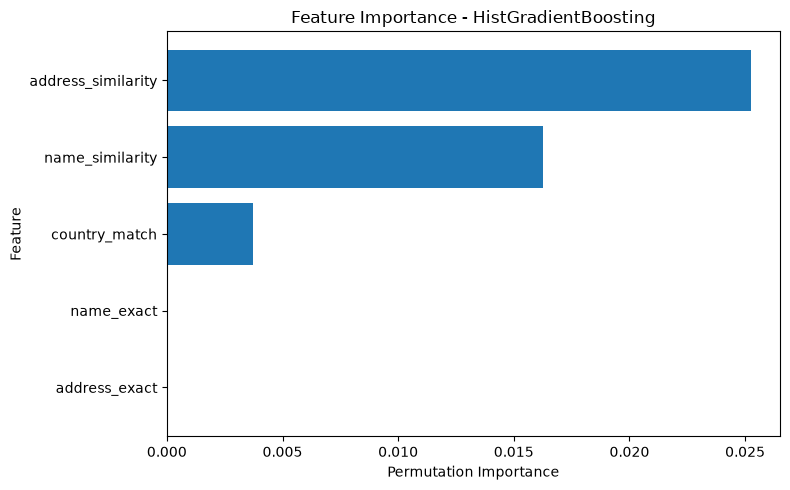

In [53]:
# ==========================================
# STEP 49: FEATURE IMPORTANCE
# Using Permutation Importance
# ==========================================

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

print("Calculating feature importance...")

# Use a smaller validation sample for speed
sample_size = min(20000, len(X_val_model))

X_val_sample = X_val_model.sample(
    n=sample_size,
    random_state=42
)

y_val_sample = y_val.loc[X_val_sample.index]

# Permutation importance
perm_result = permutation_importance(
    model,
    X_val_sample,
    y_val_sample,
    n_repeats=3,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": perm_result.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

print("\n========================================")
print("FEATURE IMPORTANCE")
print("========================================")
print(importance_df)

# Plot
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - HistGradientBoosting")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [54]:
# ==========================================
# STEP 50: THRESHOLD ANALYSIS
# ==========================================

import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:
    pred = (y_val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred)
    })

threshold_df = pd.DataFrame(results)

print("THRESHOLD ANALYSIS")
print("=" * 70)
print(threshold_df.round(4).to_string(index=False))

THRESHOLD ANALYSIS
 Threshold  Accuracy  Precision  Recall     F1
      0.10    0.9946     0.9972  0.9971 0.9971
      0.15    0.9934     0.9980  0.9949 0.9965
      0.20    0.9920     0.9987  0.9927 0.9957
      0.25    0.9908     0.9991  0.9911 0.9951
      0.30    0.9901     0.9993  0.9902 0.9947
      0.35    0.9896     0.9993  0.9896 0.9944
      0.40    0.9888     0.9994  0.9886 0.9940
      0.45    0.9883     0.9995  0.9880 0.9937
      0.50    0.9872     0.9996  0.9868 0.9932
      0.55    0.9866     0.9997  0.9860 0.9928
      0.60    0.9858     0.9997  0.9851 0.9924
      0.65    0.9853     0.9997  0.9846 0.9921
      0.70    0.9835     0.9998  0.9826 0.9911
      0.75    0.9826     0.9998  0.9817 0.9907
      0.80    0.9803     0.9999  0.9792 0.9894
      0.85    0.9786     0.9999  0.9774 0.9885
      0.90    0.9751     0.9999  0.9736 0.9866


In [55]:
# ==========================================
# STEP 51: FINAL THRESHOLD TEST EVALUATION
# ==========================================

selected_threshold = 0.10

# Apply threshold to untouched test probabilities
y_test_pred_threshold = (
    y_test_prob >= selected_threshold
).astype(int)

threshold_test_accuracy = accuracy_score(
    y_test, y_test_pred_threshold
)

threshold_test_precision = precision_score(
    y_test, y_test_pred_threshold
)

threshold_test_recall = recall_score(
    y_test, y_test_pred_threshold
)

threshold_test_f1 = f1_score(
    y_test, y_test_pred_threshold
)

print("\n========================================")
print("FINAL TEST RESULTS @ THRESHOLD 0.10")
print("========================================")

print(f"Accuracy :  {threshold_test_accuracy:.4f}")
print(f"Precision:  {threshold_test_precision:.4f}")
print(f"Recall   :  {threshold_test_recall:.4f}")
print(f"F1 Score :  {threshold_test_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_threshold
))


FINAL TEST RESULTS @ THRESHOLD 0.10
Accuracy :  0.9944
Precision:  0.9971
Recall   :  0.9969
F1 Score :  0.9970

Confusion Matrix:
[[ 47813   2187]
 [  2345 761492]]


In [56]:

import joblib
import json

# Save trained model
joblib.dump(model, "entity_matching_model.pkl")

# Save model configuration
model_config = {
    "features": feature_cols,
    "threshold": 0.10,
    "model_type": "HistGradientBoostingClassifier",
    "validation_f1": 0.9971,
    "test_accuracy": 0.9944,
    "test_precision": 0.9971,
    "test_recall": 0.9969,
    "test_f1": 0.9970
}

with open("model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

print("========================================")
print("MODEL SAVED SUCCESSFULLY")
print("========================================")
print("entity_matching_model.pkl")
print("model_config.json")
print("\nThreshold:", model_config["threshold"])

MODEL SAVED SUCCESSFULLY
entity_matching_model.pkl
model_config.json

Threshold: 0.1
